# Détection d'une figure et reconnaissance de sa forme (option B)
Dataset synthétique (cercles, carrés, triangles) → apprentissage → feature maps → prédiction (boîte + forme) → évaluation.

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_2 import make_example
from src.detector import Detector, STRIDE, CLASSES, predict_class
from src.visualize import show_images, show_feature_maps, show_detections
from src.detector import code
from src.train import evaluate, train

MODEL_SIZE = 64        
assert MODEL_SIZE % STRIDE == 0   

## 1. Génération du dataset
Le générateur fourni avec le TP produit des images contenant une seule figure : un cercle, un carré ou un triangle, dans l'une de 5 couleurs, avec une position et une taille aléatoires. On génère directement les images à la taille attendue par le modèle.

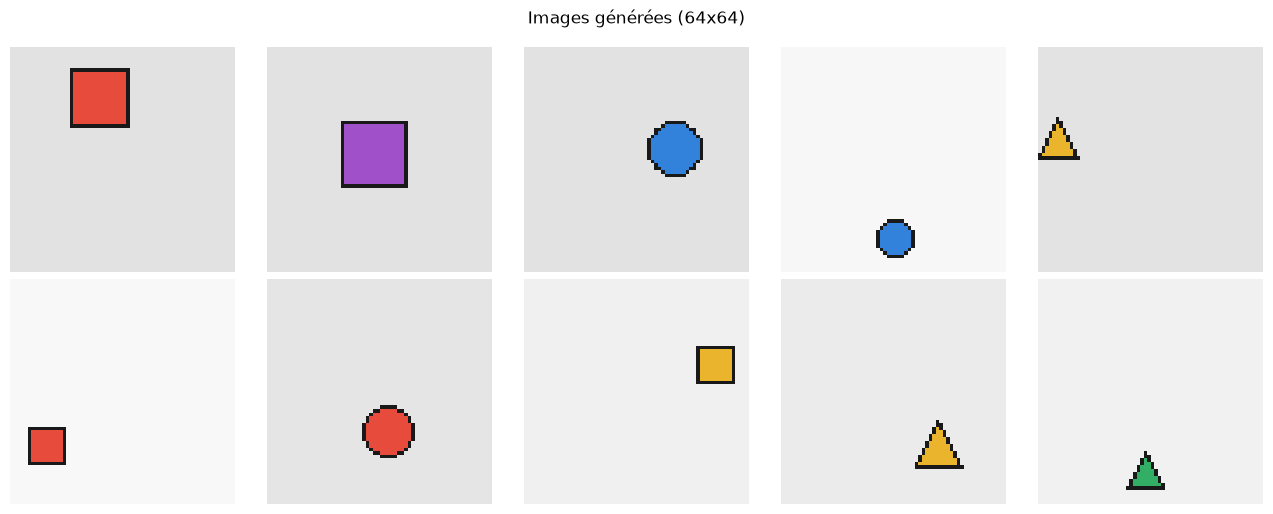

In [27]:
rng = random.Random(123)
pil_images = [make_example(MODEL_SIZE, rng)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [28]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

images = torch.stack([to_tensor(im) for im in pil_images])
print(images.shape)

torch.Size([10, 3, 64, 64])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 2000 images pour l'entraînement et 400 images indépendantes pour la validation (le premier essai avait été fait avec 200 et 40). Chaque étiquette `cx cy w h classe` (en pixels) est encodée en cible `(8, G, G)` : 5 canaux pour la boîte (présence, dx, dy, w, h) et 3 canaux pour la classe (cercle, carré, triangle), remplis seulement dans la case du centre.

In [29]:
def make_dataset(count, seed):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, rng)
        cx, cy, width, height, class_id = map(float, label.split())
        dataset_images.append(to_tensor(image))
        targets.append(code(cx, cy, width, height, int(class_id), size=MODEL_SIZE))
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

## 3. Entraînement du modèle
Le réseau donne 8 nombres par case de la grille : 5 pour la boîte et 3 scores de classe. La perte est la somme de trois parties : la présence (BCE), la boîte (MSE, canaux 1 à 4) et la classe (entropie croisée).

On entraîne pendant 50 époques (Adam, taux d'apprentissage 3e-3, batch de 64). À chaque époque, on mesure sur la validation l'IoU moyen, la proportion d'IoU > 0,5 et l'accuracy de classification, et on les enregistre pour TensorBoard.

In [30]:
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50

import tempfile
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

# Les logs sont écrits hors du dossier synchronisé ownCloud (TensorBoard/TensorFlow
# n'y accède pas correctement : "runs/demo is not a directory").
LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Logs TensorBoard :", LOG_ROOT)

torch.manual_seed(0)
train_set = make_dataset(TRAIN_SAMPLES, seed=7)
val_set = make_dataset(VAL_SAMPLES, seed=8)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Detector()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
run_dir = LOG_ROOT / datetime.now().strftime('%Y%m%d-%H%M%S')
with SummaryWriter(log_dir=str(run_dir)) as writer:
         for epoch in range(1, EPOCHS + 1):
          mean_loss = train(model, train_loader, optimizer)
          val_iou, val_accuracy, val_class_acc = evaluate(model, val_loader, MODEL_SIZE)
          writer.add_scalar("Loss/train", mean_loss, epoch)
          writer.add_scalar("IoU/validation", val_iou, epoch)
          writer.add_scalar("Accuracy/validation_IoU_gt_0.5", val_accuracy, epoch)
          writer.add_scalar("Accuracy/validation_classe", val_class_acc, epoch)
          print(f"epoch {epoch:2d}  loss {mean_loss:.4f}  "
                f"val IoU {val_iou:.3f}  IoU>0.5 {val_accuracy:.0%}  classe {val_class_acc:.0%}")

model.eval();

Logs TensorBoard : C:\Users\MSI\AppData\Local\Temp\tb_runs\demo
epoch  1  loss 1.7828  val IoU 0.417  IoU>0.5 28%  classe 52%
epoch  2  loss 0.8793  val IoU 0.550  IoU>0.5 61%  classe 78%
epoch  3  loss 0.4991  val IoU 0.603  IoU>0.5 74%  classe 92%
epoch  4  loss 0.3172  val IoU 0.625  IoU>0.5 76%  classe 94%
epoch  5  loss 0.2499  val IoU 0.646  IoU>0.5 82%  classe 97%
epoch  6  loss 0.2042  val IoU 0.660  IoU>0.5 84%  classe 99%
epoch  7  loss 0.1720  val IoU 0.679  IoU>0.5 88%  classe 98%
epoch  8  loss 0.1496  val IoU 0.682  IoU>0.5 87%  classe 99%
epoch  9  loss 0.1402  val IoU 0.696  IoU>0.5 88%  classe 99%
epoch 10  loss 0.1311  val IoU 0.684  IoU>0.5 88%  classe 99%
epoch 11  loss 0.1272  val IoU 0.706  IoU>0.5 90%  classe 100%
epoch 12  loss 0.1159  val IoU 0.713  IoU>0.5 91%  classe 100%
epoch 13  loss 0.1057  val IoU 0.698  IoU>0.5 88%  classe 100%
epoch 14  loss 0.1056  val IoU 0.727  IoU>0.5 93%  classe 100%
epoch 15  loss 0.1014  val IoU 0.714  IoU>0.5 90%  classe 100%
e

In [31]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\MSI\tensorboard\tpml\Scripts\python.exe" -m tensorboard.main --logdir "C:\Users\MSI\AppData\Local\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Code 1 — Visualiser les cartes de caractéristiques et les poids d’un filtre
Ce code calcule les cartes de caractéristiques pour les images contenues dans images, puis affiche les cartes des trois premières images. Il affiche aussi les poids d’un filtre de la première couche convolutive.

But : observer les activations du réseau et les valeurs apprises par un filtre.

torch.Size([10, 32, 8, 8])


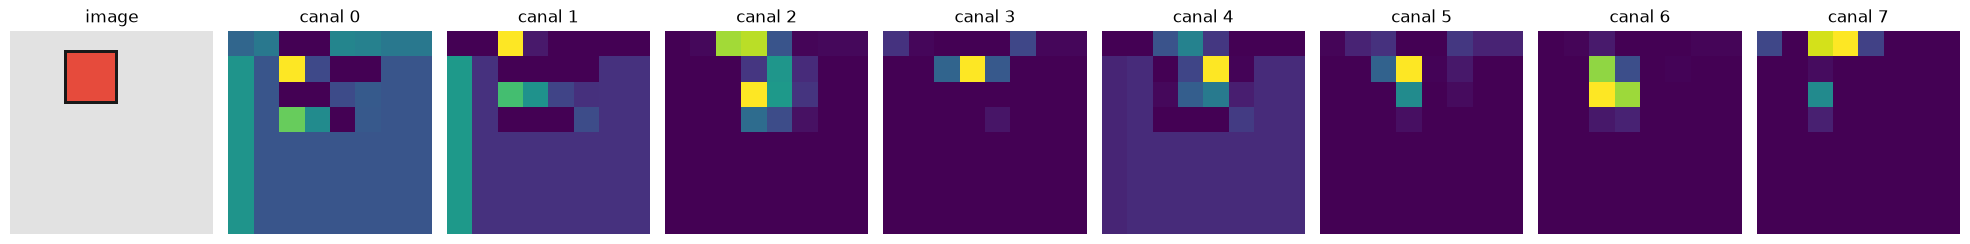

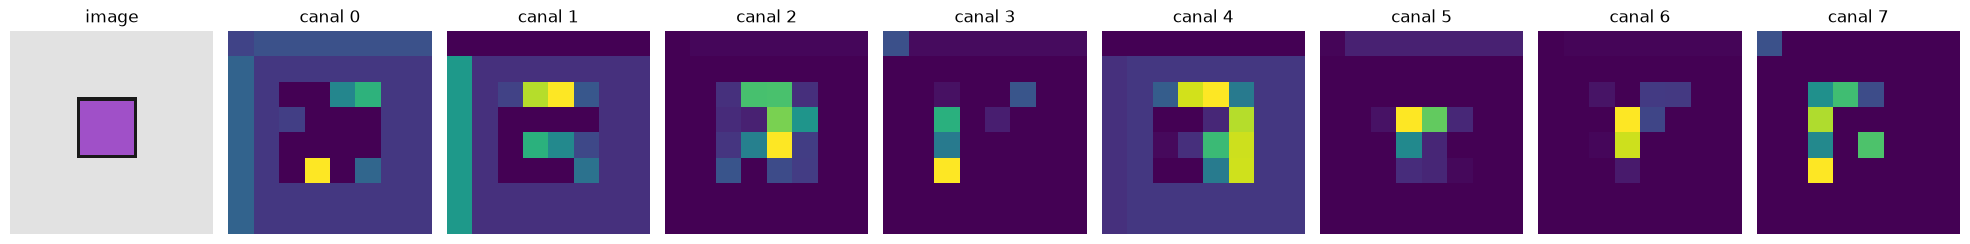

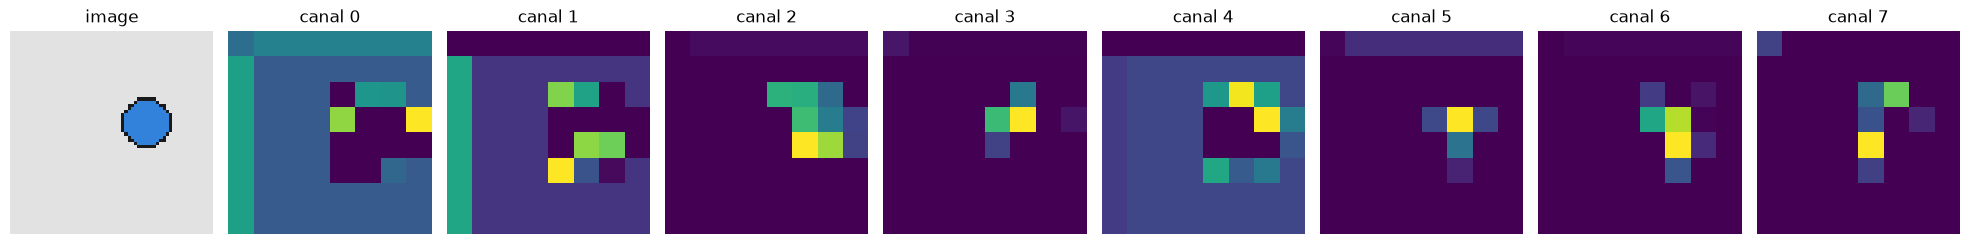

tensor([[ 0.1605,  0.1522, -0.1612],
        [ 0.1131, -0.0097, -0.0398],
        [-0.1365, -0.0927, -0.2121]], grad_fn=<SelectBackward0>)


In [32]:
with torch.no_grad():
    maps = model.feature_maps(images)   # (N, 32, 8, 8)
print(maps.shape)
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

print(model.backbone[0].weight[3, 0, :, :])

## 5. Prédiction, décodage et NMS : une boîte et une forme par image
`predict_class` décode les 64 boîtes, garde la meilleure avec le NMS, puis lit la forme prédite dans la case de cette boîte (le plus grand des 3 scores de classe). Chaque image s'affiche avec sa boîte verte, le nom de la forme et le score.

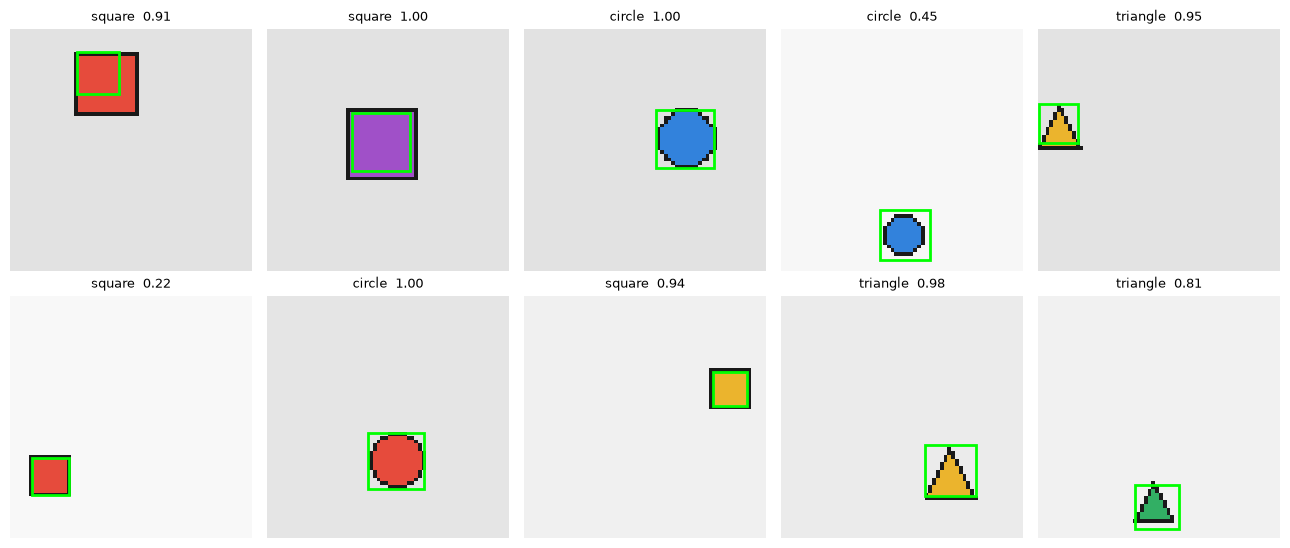

In [33]:
with torch.no_grad():
    logits = model(images)
results = [predict_class(l, MODEL_SIZE) for l in logits]
labels = [CLASSES[c] for _, _, c in results]
show_detections(list(images), [b for b, _, _ in results], [s for _, s, _ in results], labels=labels)

In [34]:
from src.detector import iou, predict_class, NUM_CLASSES

model.eval()
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)   # lignes = vraie classe, colonnes = classe prédite
iou_par_classe = {c: [] for c in range(NUM_CLASSES)}

with torch.no_grad():
    for images_batch, targets in val_loader:
        logits = model(images_batch)
        grid = targets.shape[-1]
        for logit, target in zip(logits, targets):
            box, _, pred_class = predict_class(logit, MODEL_SIZE)
            row, col = divmod(int(target[0].argmax()), grid)
            _, dx, dy, w, h = target[:5, row, col].tolist()
            true_class = int(target[5:, row, col].argmax())
            cx, cy = (col + dx) * MODEL_SIZE / grid, (row + dy) * MODEL_SIZE / grid
            truth = torch.tensor([cx - w * MODEL_SIZE / 2, cy - h * MODEL_SIZE / 2,
                                  cx + w * MODEL_SIZE / 2, cy + h * MODEL_SIZE / 2])
            confusion[true_class, pred_class] += 1
            iou_par_classe[true_class].append(float(iou(box, truth[None])[0]))

print("Matrice de confusion (lignes = vraie classe, colonnes = classe prédite)")
print(" " * 12, *[f"{name:>9}" for name in CLASSES])
for i, name in enumerate(CLASSES):
    print(f"{name:>12}", *[f"{v:>9}" for v in confusion[i]])
print()
for c, name in enumerate(CLASSES):
    print(f"IoU moyen pour {name} : {np.mean(iou_par_classe[c]):.3f}")

Matrice de confusion (lignes = vraie classe, colonnes = classe prédite)
                circle    square  triangle
      circle       122         0         0
      square         0       135         0
    triangle         0         0       143

IoU moyen pour circle : 0.834
IoU moyen pour square : 0.707
IoU moyen pour triangle : 0.746


Code 2 — Visualiser les cartes pour chaque forme
Ce code parcourt le jeu de validation et sélectionne automatiquement une image de chaque classe : cercle, carré et triangle. Il calcule ensuite les cartes de caractéristiques et les affiche pour chaque image.

But : comparer les activations du réseau pour les différentes formes.

circle


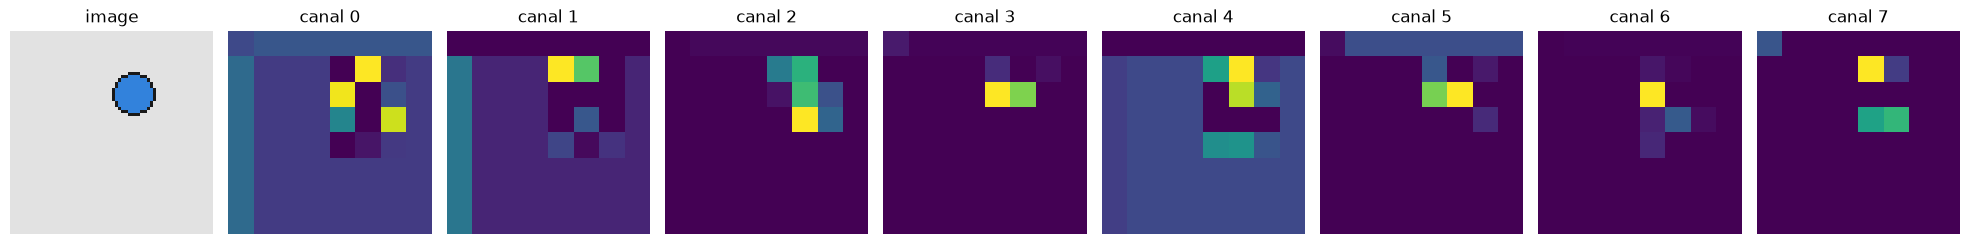

square


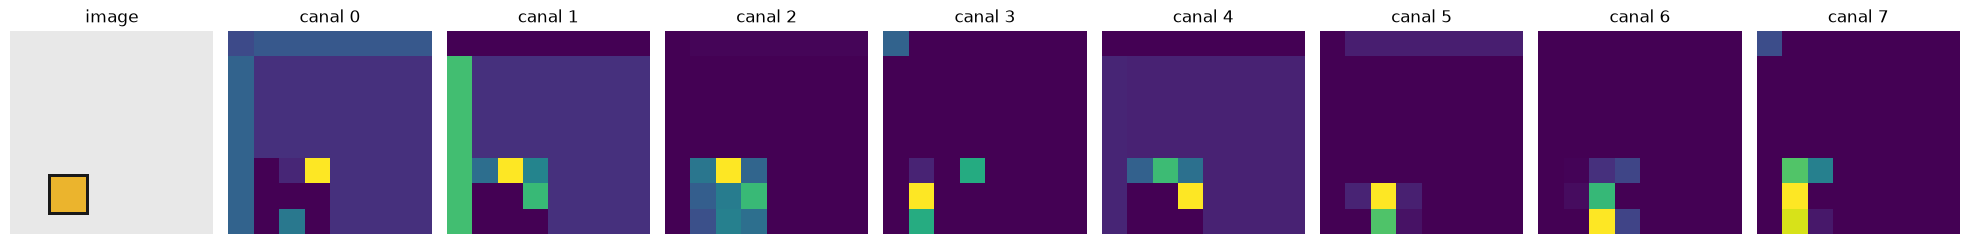

triangle


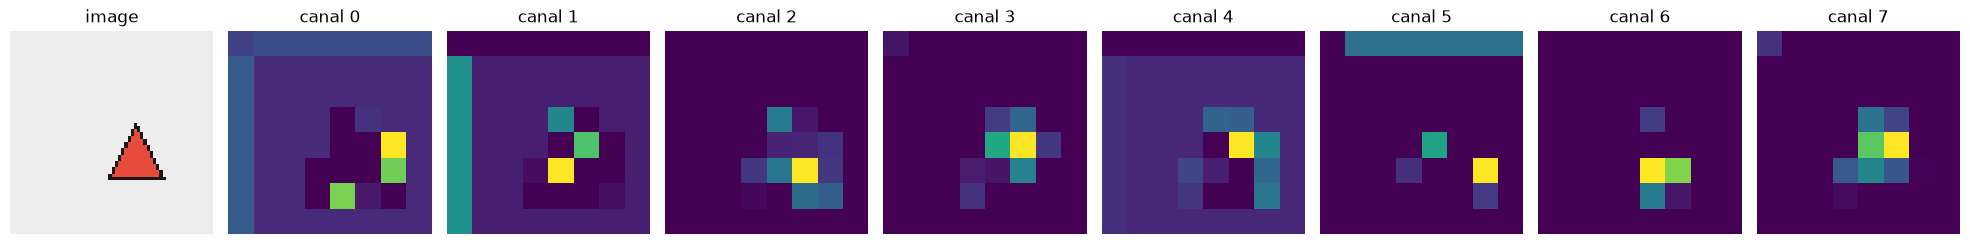

In [35]:
from src.detector import NUM_CLASSES

# Une image de validation pour chaque forme
exemples = {}
for image, target in val_set:
    row, col = divmod(int(target[0].argmax()), target.shape[-1])
    classe = int(target[5:, row, col].argmax())
    if classe not in exemples:
        exemples[classe] = image
    if len(exemples) == NUM_CLASSES:
        break

model.eval()
for classe in sorted(exemples):
    print(CLASSES[classe])
    with torch.no_grad():
        maps = model.feature_maps(exemples[classe][None])[0]   # (32, 8, 8)
    show_feature_maps(exemples[classe], maps, n_maps=8)